# LuntiAI Machine Learning and Explainable AI
**Joseph D. Alejo · CS 24/L · CS Professional Track 6 · Explainable AI 10–12**  
**Professor: Iris Mae C. Mendoza, MIT · October 30, 2026**

This notebook adapts the existing Technopreneurship project into a reproducible XAI study. It trains and evaluates the crop classifier, checks that it agrees with the saved application model, and explains its decisions using the same explanation function as the API. The contribution is a verified explanation workflow and its evaluation, rather than a claim that the original system or dataset is new.

**Research question:** How can LuntiAI expose and verify the contributions behind a crop classification, including why its selected class scores above the runner-up?

**Important boundary:** the 120,000 records are generated synthetic crop profiles. Held-out results measure performance on that generator's distribution; they do not establish performance on Philippine farms. Class probability is a model output, not crop-success probability. SHAP explains the model and does not establish causal effects, fertilizer doses, yield, or profitability.

Run from the repository with the environment in `requirements-notebook.txt`. Use Python 3.11 and Run All. Outputs go to `reports/xai/`; this notebook does not replace the deployed model files. The full run includes fresh training and 120 TreeSHAP cases and may take several minutes.

In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, log_loss
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / 'data/philippine_crop_dataset.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'api/xai.py').exists(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT / 'api'))
from xai import FEATURE_NAMES, explain_prediction
OUT = ROOT / 'reports/xai'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
versions = {p: importlib.metadata.version(p) for p in ['scikit-learn', 'shap', 'numpy', 'pandas', 'matplotlib', 'nbformat', 'nbclient']}
print('Python', platform.python_version())
display(pd.Series(versions, name='Version').to_frame())
assert versions['scikit-learn'] == '1.8.0' and versions['shap'] == '0.45.0'
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

C:\Users\naosh\AppData\Local\Temp\ipykernel_11504\3128134028.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


D:\XAI\luntiai-test-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.11.14


,Version
scikit-learn,1.8.0
shap,0.45.0
numpy,1.26.4
pandas,2.2.0
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


## 1 Data provenance and scope
The CSV and generator are included in the LuntiAI repository [1]. `data/sources.md` records the project's claimed source ranges; those citations do not establish that each generated record was observed or that the generator is agronomically validated. No farmer records, images, or text are used. The target is one of 12 crop names. Inputs are eight numerical attributes: nitrogen, phosphorus, potassium (mg/kg according to the application), temperature (°C), humidity (%), pH, rainfall (mm), and organic matter (%).

Before modeling, check missing values, duplicates, label balance, and numeric ranges. Feature order matters because the serialized forest was trained on arrays. Missingness and duplicate checks prevent obvious errors; they are not a real-world validity test. Rainfall period and field measurement protocols would need clarification before field deployment.

,Data audit
rows,120000
features,8
classes,12
missing_cells,0
duplicate_rows,0
duplicate_inputs,0
dataset_sha256,10a7f18fa4c1d97d747a415f92c0dc4e540c49ba631e81...


,N,P,K,temperature,humidity,ph,rainfall,OM
count,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00
mean,74.70,44.40,82.96,27.34,73.75,6.11,158.30,2.59
std,32.62,14.91,39.76,2.32,9.59,0.57,60.49,0.80
min,10.00,10.00,15.00,20.00,45.00,4.50,50.00,0.50
25%,48.70,33.60,52.10,25.80,66.88,5.73,109.78,2.01
50%,72.00,43.60,76.40,27.37,74.88,6.11,149.22,2.56
75%,98.50,54.20,106.00,28.93,81.05,6.49,202.57,3.13
max,180.00,100.00,250.00,35.00,95.00,8.00,350.00,6.00


,Rows
label,
Rice,12000
Coconut,12000
Banana,12000
Durian,11000
Cacao,11000
Corn,10000
Mango,9000
Sweet Potato,9000
Cassava,9000


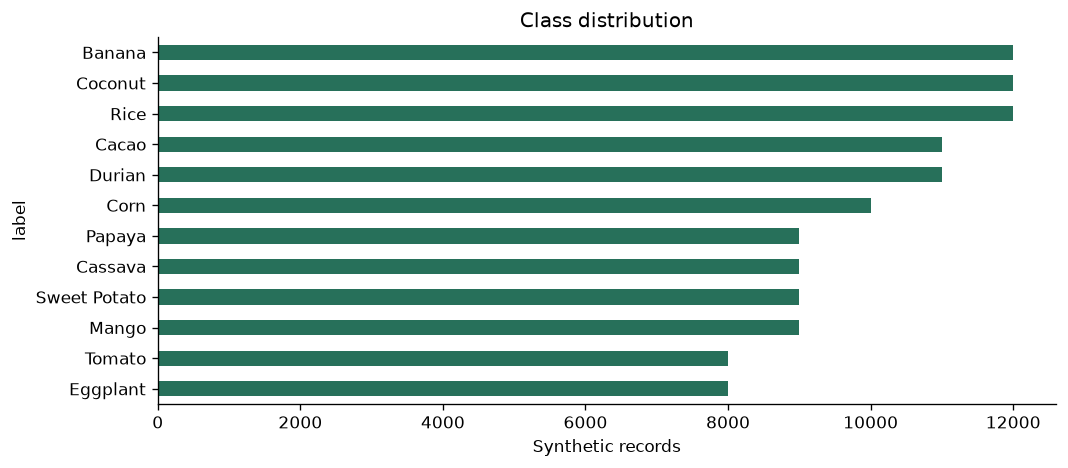

In [2]:
data_path = ROOT / 'data/philippine_crop_dataset.csv'
df = pd.read_csv(data_path)
assert list(df.columns) == FEATURE_NAMES + ['label']
assert not df.isna().any().any()
assert np.isfinite(df[FEATURE_NAMES].to_numpy()).all()
assert df.label.nunique() == 12
audit = {'rows': len(df), 'features': len(FEATURE_NAMES), 'classes': df.label.nunique(),
         'missing_cells': int(df.isna().sum().sum()), 'duplicate_rows': int(df.duplicated().sum()),
         'duplicate_inputs': int(df.duplicated(FEATURE_NAMES).sum()),
         'dataset_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest()}
display(pd.Series(audit).to_frame('Data audit'))
display(df[FEATURE_NAMES].describe().round(2))
display(df.label.value_counts().rename('Rows').to_frame())
fig, ax = plt.subplots(figsize=(9, 4))
df.label.value_counts().sort_values().plot.barh(ax=ax, color='#27705a')
ax.set(xlabel='Synthetic records', title='Class distribution')
fig.tight_layout(); fig.savefig(OUT / 'class-distribution.png'); plt.show()

## 2 Split and modeling decisions
Use the original stratified 80/20 split with seed 42: 96,000 training and 24,000 test rows. Fit the forest only on training rows. The target encoder maps known crop names to integers; it does not learn feature statistics. There is no imputation or scaling because inputs are complete and tree thresholds do not require standardized units.

Random Forest retains the existing 200 trees, maximum depth 25, minimum split size 5, minimum leaf size 2, square-root feature sampling, and balanced class weights. Trees can represent nonlinear thresholds and interactions in tabular data. Averaging many trees reduces dependence on one tree, but makes the combined decision harder to inspect, motivating TreeSHAP. These are inherited settings, **not the outcome of a documented hyperparameter search**.

A majority classifier tests whether learning improves on class frequency. A depth-4 decision tree provides a compact, intrinsically interpretable comparator. This limited comparison does not prove the forest is the best possible algorithm. Test data are used for evaluation, not parameter selection. Because this split has already been evaluated during the original project, it is a reproducibility holdout, not a newly sequestered final test. Future tuning should use cross-validation within training data and a separate untouched field dataset.

In [3]:
encoder = LabelEncoder().fit(df.label)
X = df[FEATURE_NAMES].to_numpy()
y = encoder.transform(df.label)
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y)
assert not set(train_idx).intersection(test_idx)
assert not df.iloc[train_idx][FEATURE_NAMES].merge(df.iloc[test_idx][FEATURE_NAMES], on=FEATURE_NAMES).shape[0]
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
rf = RandomForestClassifier(n_estimators=200, max_depth=25, min_samples_split=5,
    min_samples_leaf=2, max_features='sqrt', random_state=SEED, n_jobs=-1, class_weight='balanced')
models = {'Majority baseline': DummyClassifier(strategy='most_frequent'),
          'Depth 4 decision tree': DecisionTreeClassifier(max_depth=4, random_state=SEED, class_weight='balanced'),
          'Existing RF configuration': rf}
records = []
for name, estimator in models.items():
    start = time.perf_counter()
    estimator.fit(X_train, y_train)
    prediction = estimator.predict(X_test)
    records.append({'model': name, 'accuracy': accuracy_score(y_test, prediction),
                    'macro_f1': f1_score(y_test, prediction, average='macro'),
                    'fit_and_predict_seconds': time.perf_counter()-start})
    print(name, 'finished')
metrics = pd.DataFrame(records).set_index('model')
metrics.to_csv(OUT / 'model-comparison.csv')
display(metrics.round(5))

Majority baseline finished


Depth 4 decision tree finished


Existing RF configuration finished


,accuracy,macro_f1,fit_and_predict_seconds
model,,,
Majority baseline,0.10000,0.01515,0.00828
Depth 4 decision tree,0.57433,0.54364,0.22566
Existing RF configuration,0.85621,0.84934,6.79283


## 3 Prediction evaluation and application parity
Accuracy summarizes the fraction classified correctly. Macro F1 gives each crop equal weight and exposes weaker classes that a single accuracy value can hide. The confusion matrix identifies which crop profiles overlap under the generator. Log loss checks the full probability vector; its value is descriptive here because probability calibration has not been established.

Compare the freshly trained forest against the trusted saved project model on the same test rows. Agreement links the notebook to the application. The serialized files require scikit-learn 1.8.0, so the project dependency is aligned with that version. Do not load untrusted pickle files.

,precision,recall,f1-score,support
Banana,0.9496,0.9417,0.9456,2400.0000
Cacao,0.7995,0.8355,0.8171,2200.0000
Cassava,0.8915,0.8811,0.8863,1800.0000
Coconut,0.8938,0.8383,0.8652,2400.0000
Corn,0.8808,0.9130,0.8966,2000.0000
Durian,0.8585,0.8800,0.8691,2200.0000
Eggplant,0.6597,0.6350,0.6471,1600.0000
Mango,0.8654,0.8678,0.8666,1800.0000
Papaya,0.7961,0.7939,0.7950,1800.0000
Rice,0.9326,0.9167,0.9246,2400.0000


Multiclass log loss: 0.4321437575374974


Maximum probability difference, retrained vs saved: 3.3306690738754696e-16


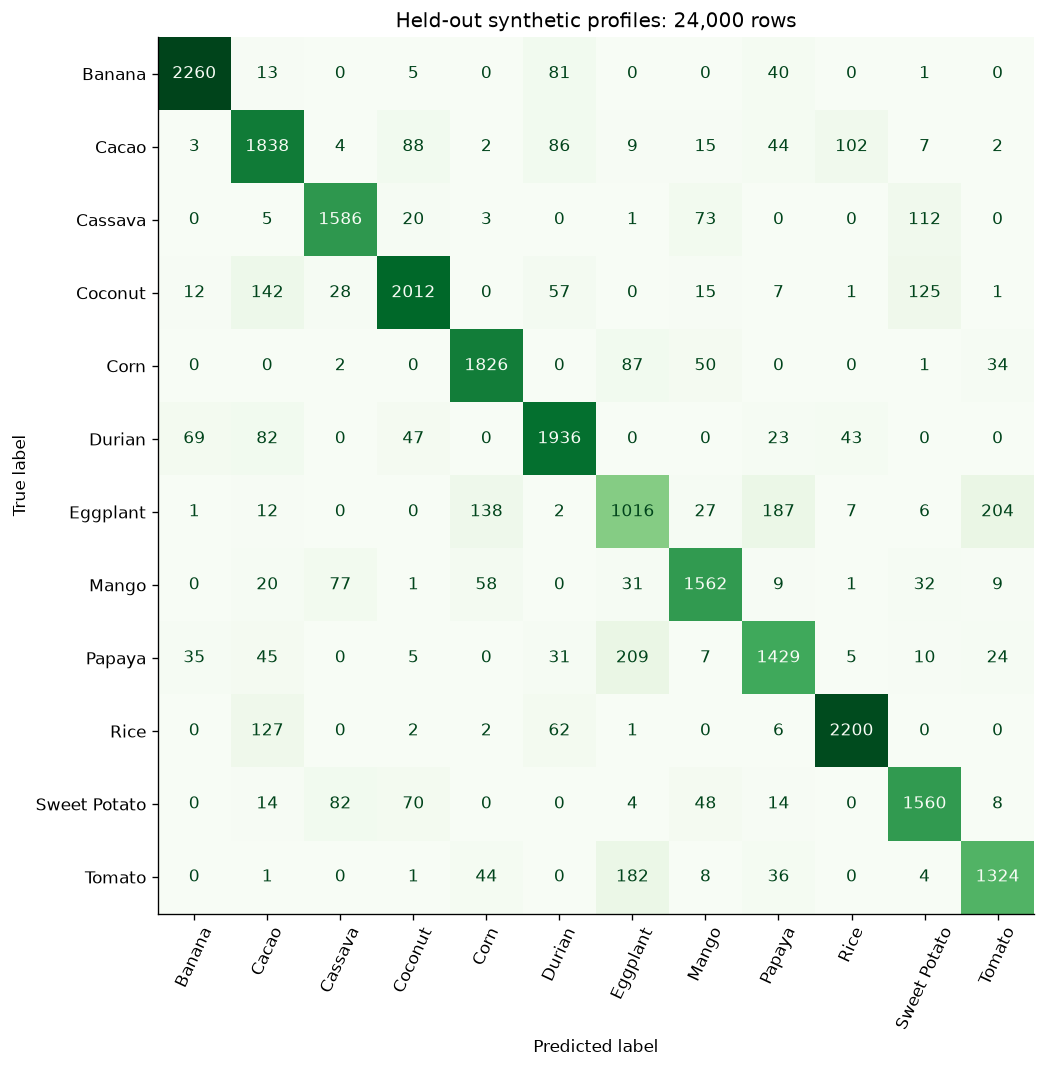

In [4]:
pred = rf.predict(X_test)
prob = rf.predict_proba(X_test)
report = pd.DataFrame(classification_report(y_test, pred, target_names=encoder.classes_, output_dict=True)).T
report.to_csv(OUT / 'classification-report.csv')
display(report.round(4))
print('Multiclass log loss:', log_loss(y_test, prob))
with warnings.catch_warnings(record=True) as captured:
    saved = joblib.load(ROOT / 'model/crop_model.pkl')
    saved_encoder = joblib.load(ROOT / 'model/label_encoder.pkl')
assert not any('Trying to unpickle estimator' in str(w.message) for w in captured)
assert np.array_equal(saved_encoder.classes_, encoder.classes_)
saved_prob = saved.predict_proba(X_test)
parity_error = float(np.max(np.abs(saved_prob-prob)))
print('Maximum probability difference, retrained vs saved:', parity_error)
assert np.allclose(saved_prob, prob, atol=1e-12)
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=encoder.classes_, ax=ax,
    xticks_rotation=65, cmap='Greens', colorbar=False)
ax.set_title('Held-out synthetic profiles: 24,000 rows')
fig.tight_layout(); fig.savefig(OUT / 'confusion-matrix.png'); plt.show()

## 4 XAI taxonomy and reference semantics

| Dimension | LuntiAI implementation | Reason and boundary |
|---|---|---|
| Agnosticity | Model-specific TreeSHAP | Uses the forest's structure; SHAP is a framework, not a guarantee of model agnosticism. KernelSHAP below is model-agnostic. |
| Scope | Local per input and per crop; global aggregation on a declared sample | A single explanation cannot establish model-wide importance. |
| Data type | Structured numerical tabular inputs; categorical multiclass target | No text or image explanations. |
| Timing | Post-hoc | Explains an already trained ensemble; embedding it in the app does not make the ensemble intrinsically interpretable. |
| Explanation type | Signed additive feature attribution | Not a decision rule, example-based explanation, causal effect, or counterfactual recourse. |
| Output | One class probability | Positive values raise that class output relative to the baseline; negative values lower it. |
| Reference | Tree-path-dependent training path frequencies | No explicit background rows; not a physical average farm and not automatically exact conditional inference. |
| Presentation | Complete contributions, baseline, output, and runner-up score gap | Numerical values support the visual explanation and an additivity check. |

SHAP attributes the difference between a model output and its reference value to features using a Shapley-value framework [2]. TreeSHAP exploits tree structure [3]. We explicitly set `feature_perturbation='tree_path_dependent'` and `model_output='raw'` to match the existing deployment [4]. For this scikit-learn forest, the raw output is the class probability, verified numerically below; for other tree models raw may mean margin or log odds. Do not generalize that output interpretation without checking.

For class c, **f_c(x) = base_c + sum of the eight SHAP contributions**. The baseline reflects the chosen reference and class weighting. Additivity checks numerical reconstruction, not causality, model correctness, or whether a person understands the explanation. Correlated features and alternative reference assumptions can change attribution.

In [5]:
explainer = shap.TreeExplainer(rf, feature_perturbation='tree_path_dependent', model_output='raw')
assert explainer.data is None
assert explainer.feature_perturbation == 'tree_path_dependent'
classes = encoder.inverse_transform(rf.classes_)
display(pd.Series(explainer.expected_value, index=classes, name='Class reference probability').to_frame())

,Class reference probability
Banana,0.083338
Cacao,0.083356
Cassava,0.083365
Coconut,0.083422
Corn,0.083297
Durian,0.083476
Eggplant,0.083240
Mango,0.083304
Papaya,0.083251
Rice,0.083408


## 5 Local explanation using the actual API helper
Use a fixed held-out case (the first Banana-labeled row in the seeded test order), chosen without selecting a large SHAP value. Explain the predicted class, which may differ from its true label. Display all eight features, including small or negative contributions. Values are in probability units; multiply by 100 for percentage points. A change of +0.10 means +10 percentage points, not a 10% relative increase.

The API helper checks output dimensions, finite values, selected-class alignment, and reconstruction for **all 12 classes**. It returns the same schema used by the web interface. The interface scales bars by the largest absolute contribution and preserves signed numeric values; the old interface clipped multiple bars to full width and omitted some contributions.

,feature,input_value,value,alternative_value,difference,contribution_pp,difference_pp
0,N,131.30,0.313457,0.060042,0.253414,31.345674,25.341427
1,K,120.50,0.177705,0.039088,0.138617,17.770486,13.861689
2,rainfall,199.36,0.133789,-0.044606,0.178395,13.378888,17.839514
3,humidity,81.60,0.120803,-0.104431,0.225234,12.080330,22.523438
4,OM,4.38,0.119922,-0.028099,0.148020,11.992158,14.802022
5,ph,5.42,0.015299,-0.005328,0.020627,1.529891,2.062735
6,temperature,28.22,0.014216,0.009020,0.005195,1.421553,0.519535
7,P,44.10,0.013615,-0.006080,0.019696,1.361522,1.969560


True label: Banana
Selected class: Banana
Baseline + contributions = output: 0.0833378287768109 + 0.9088050283660116 = 0.9921428571428572
Maximum all-class reconstruction error: 4.260480856999038e-14


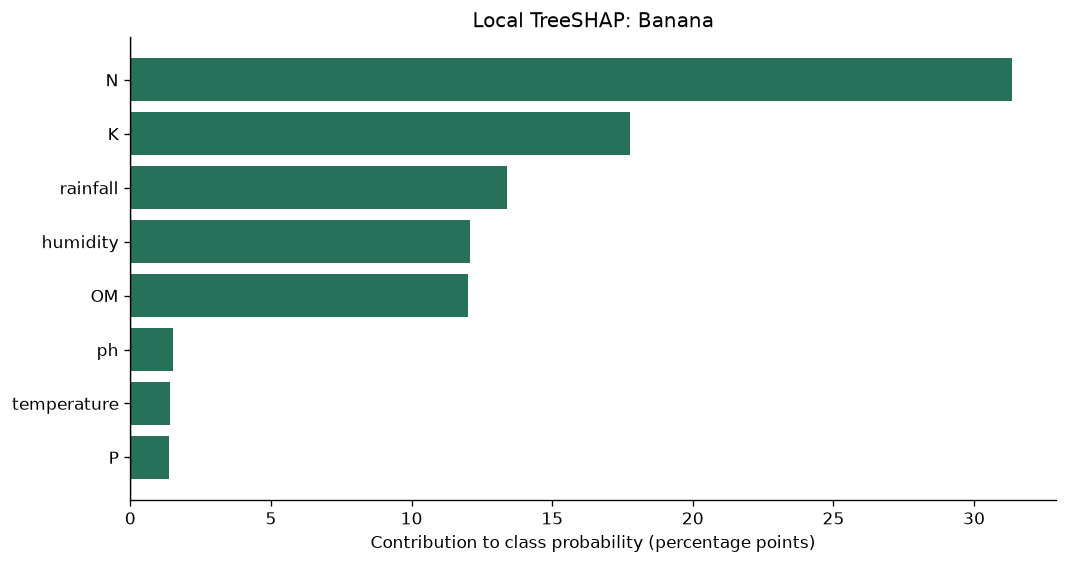

In [6]:
local_pos = int(np.flatnonzero(y_test == encoder.transform(['Banana'])[0])[0])
row = X_test[local_pos:local_pos+1]
local_prob = rf.predict_proba(row)[0]
selected_class = int(local_prob.argmax())
local = explain_prediction(explainer, row, local_prob, classes, selected_class)
local_table = pd.DataFrame(local['contributions'])
display(local_table.assign(contribution_pp=local_table.value*100, difference_pp=local_table.difference*100))
print('True label:', encoder.inverse_transform([y_test[local_pos]])[0])
print('Selected class:', local['explained_class'])
print('Baseline + contributions = output:', local['base_value'], '+', local_table.value.sum(), '=', local['prediction_value'])
print('Maximum all-class reconstruction error:', local['max_additivity_error'])
assert len(local_table) == 8
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_table = local_table.sort_values('value')
ax.barh(plot_table.feature, plot_table.value*100, color=['#aa503b' if v < 0 else '#27705a' for v in plot_table.value])
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Contribution to class probability (percentage points)', title=f"Local TreeSHAP: {local['explained_class']}")
fig.tight_layout(); fig.savefig(OUT / 'local-attribution.png'); plt.show()

## 6 Why the selected crop over the runner-up
Subtract the runner-up explanation from the selected-class explanation. The resulting feature differences reconstruct **p(selected) − p(runner-up)** using the same reference semantics. Positive differences favor the selected class in this score comparison; negative differences favor the runner-up. This is a contrast of two outputs at the same input, not a counterfactual instruction for changing crops or soil properties.

Banana: 99.2143%; Papaya: 0.2857%
Gap = 0.0087 baseline pp + 98.9199 contribution pp = 98.9286 pp


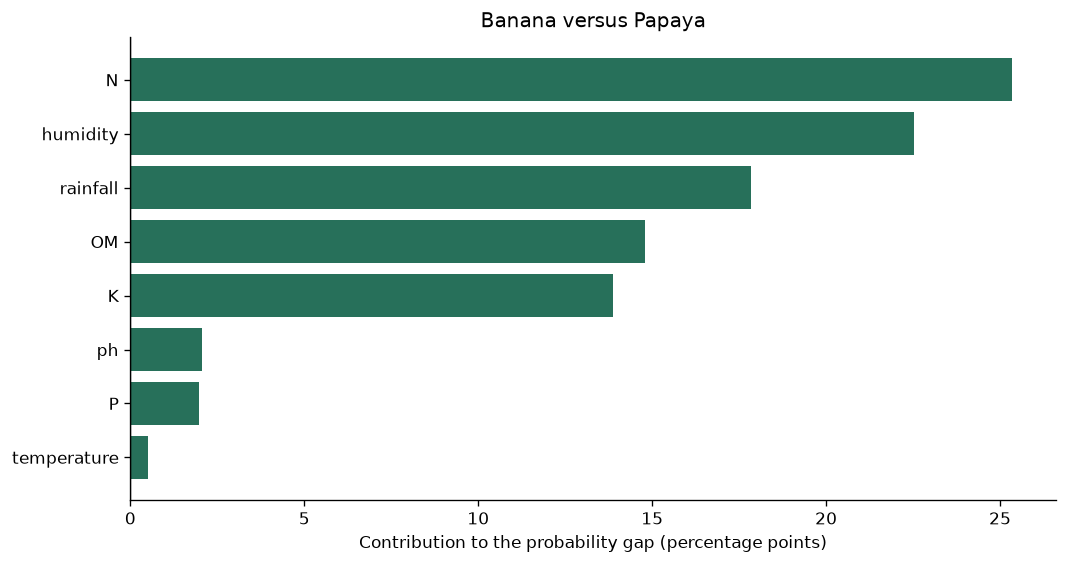

In [7]:
alt = local['alternative']
gap_reconstructed = alt['base_gap'] + local_table.difference.sum()
assert np.isclose(gap_reconstructed, alt['probability_gap'], atol=1e-5)
print(f"{local['explained_class']}: {local['prediction_value']:.4%}; {alt['class']}: {alt['prediction_value']:.4%}")
print(f"Gap = {alt['base_gap']*100:.4f} baseline pp + {local_table.difference.sum()*100:.4f} contribution pp = {gap_reconstructed*100:.4f} pp")
fig, ax = plt.subplots(figsize=(9, 4.8))
contrast = local_table.sort_values('difference')
ax.barh(contrast.feature, contrast.difference*100, color=['#aa503b' if v < 0 else '#27705a' for v in contrast.difference])
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Contribution to the probability gap (percentage points)', title=f"{local['explained_class']} versus {alt['class']}")
fig.tight_layout(); fig.savefig(OUT / 'runner-up-comparison.png'); plt.show()

## 7 Global aggregation and coverage
Randomly select 10 test rows per true crop with a fixed seed, giving 120 explanations covering all 12 classes. Use all class outputs for each row. Compute mean absolute SHAP per feature and per output class; these values describe contribution magnitude, not direction. The overall summary averages equally across rows and output classes. Because the sample has equal crop counts, it is a **class-balanced diagnostic**, not a population-weighted estimate of farmer demand or the full test distribution.

This small sample keeps Run All practical. Report its size and sampling rule, keep the full signed values, and compare two disjoint halves as a rough ranking sensitivity diagnostic. The half-sample comparison is not a confidence interval or proof of stability. The forest's impurity importance is a different measure and must not be labeled SHAP.

20/120 explanations checked


40/120 explanations checked


60/120 explanations checked


80/120 explanations checked


100/120 explanations checked


120/120 explanations checked


,Banana,Cacao,Cassava,Coconut,Corn,Durian,Eggplant,Mango,Papaya,Rice,Sweet Potato,Tomato
N,0.06113,0.04668,0.04932,0.07680,0.03223,0.02781,0.05701,0.05997,0.07065,0.01506,0.05910,0.04143
P,0.00529,0.01271,0.04174,0.02224,0.01847,0.01305,0.02242,0.03187,0.02236,0.00528,0.02618,0.03819
K,0.06993,0.05337,0.01996,0.06291,0.09014,0.03990,0.04181,0.04196,0.05002,0.09967,0.05699,0.02996
temperature,0.00320,0.00879,0.01822,0.00642,0.01024,0.00389,0.02536,0.00494,0.03028,0.00391,0.00897,0.04042
humidity,0.03004,0.02905,0.01392,0.02663,0.01796,0.02856,0.01460,0.05508,0.03946,0.03219,0.01589,0.01645
ph,0.00708,0.02203,0.01340,0.00837,0.00194,0.03150,0.00188,0.01857,0.00347,0.00736,0.01069,0.00176
rainfall,0.03540,0.05342,0.02172,0.04164,0.04393,0.07653,0.04594,0.03218,0.04631,0.06124,0.04687,0.05324
OM,0.01739,0.04201,0.05087,0.02337,0.02229,0.01587,0.01355,0.01325,0.01259,0.01061,0.04214,0.00725


Maximum reconstruction error: 5.67323965583455e-14
Two-half global ranking Spearman correlation: 0.9761904761904763
Median explanation seconds: 0.5430221499991603


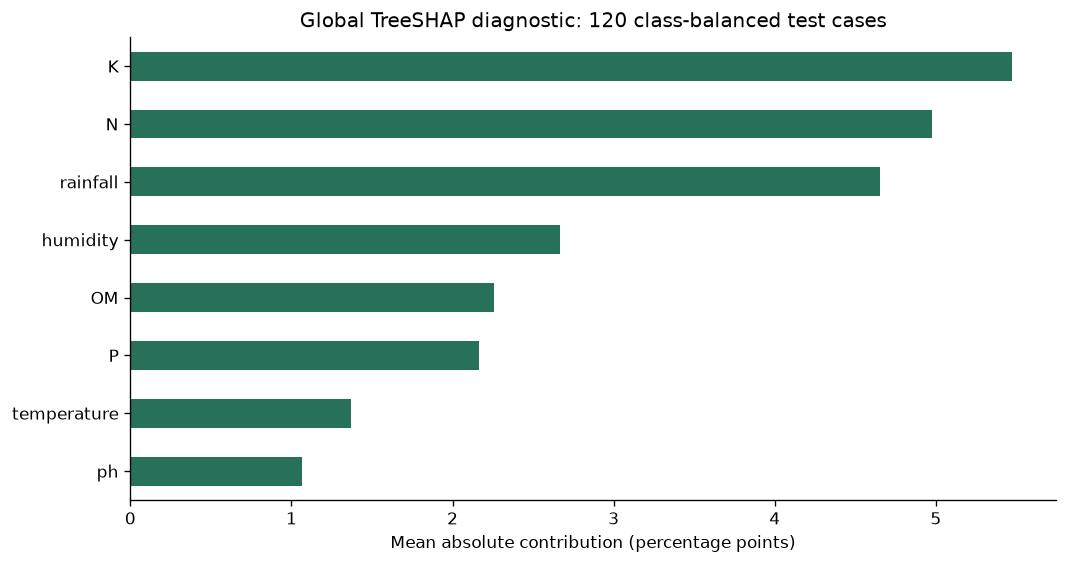

In [8]:
rng = np.random.default_rng(SEED)
sample_pos = np.concatenate([rng.choice(np.flatnonzero(y_test == c), size=10, replace=False) for c in rf.classes_])
assert len(np.unique(sample_pos)) == 120
values, durations = [], []
for i, position in enumerate(sample_pos):
    start = time.perf_counter()
    v = np.asarray(explainer.shap_values(X_test[position:position+1]))
    assert v.shape == (1, 8, 12)
    values.append(v[0]); durations.append(time.perf_counter()-start)
    if (i+1) % 20 == 0: print(f'{i+1}/120 explanations checked')
values = np.stack(values)
sample_prob = rf.predict_proba(X_test[sample_pos])
residual = float(np.max(np.abs(values.sum(axis=1) + explainer.expected_value - sample_prob)))
assert residual < 1e-5
np.savez_compressed(OUT / 'tree-shap-sample.npz', values=values, test_positions=sample_pos,
    dataset_rows=test_idx[sample_pos], base=explainer.expected_value, probabilities=sample_prob)
global_by_class = pd.DataFrame(np.abs(values).mean(axis=0), index=FEATURE_NAMES, columns=classes)
global_by_class.to_csv(OUT / 'global-shap-by-class.csv')
display(global_by_class.round(5))
overall = global_by_class.mean(axis=1).sort_values()
first = np.abs(values.reshape(12, 10, 8, 12)[:, :5]).mean(axis=(0, 1, 3))
second = np.abs(values.reshape(12, 10, 8, 12)[:, 5:]).mean(axis=(0, 1, 3))
rank_agreement = float(spearmanr(first, second).statistic)
print('Maximum reconstruction error:', residual)
print('Two-half global ranking Spearman correlation:', rank_agreement)
print('Median explanation seconds:', np.median(durations))
fig, ax = plt.subplots(figsize=(9, 4.8))
overall.mul(100).plot.barh(ax=ax, color='#27705a')
ax.set(xlabel='Mean absolute contribution (percentage points)', title='Global TreeSHAP diagnostic: 120 class-balanced test cases')
fig.tight_layout(); fig.savefig(OUT / 'global-attribution.png'); plt.show()

## 8 Model-agnostic comparison with matched references
KernelSHAP accesses only a prediction function, so it is model-agnostic [2, 4]. Comparing it directly with path-dependent TreeSHAP would confound the method with the reference definition. For a controlled one-case check, use **the same 24 training background rows** for KernelSHAP and an interventional TreeSHAP explainer, both explaining `predict_proba`. With eight features, enumerate all 254 non-empty, non-full coalitions and disable L1 feature selection.

This is a numerical consistency check for one case and a small empirical background. Interventional SHAP here replaces missing features using background rows; it does not establish a causal intervention in agriculture. Hybrid profiles can be implausible when inputs are correlated. A second training-only background shows reference sensitivity. Neither one-case timing nor attribution disagreement under different references proves that one explainer is universally better.

In [9]:
background = X_train[np.random.default_rng(SEED).choice(len(X_train), 24, replace=False)]
interventional = shap.TreeExplainer(rf, data=background, feature_perturbation='interventional', model_output='probability')
inter_values = np.asarray(interventional.shap_values(row))[0]
kernel = shap.KernelExplainer(rf.predict_proba, background)
kernel_values = np.asarray(kernel.shap_values(row, nsamples=254, l1_reg=0, silent=True))[0]
matched_difference = float(np.max(np.abs(inter_values-kernel_values)))
kernel_residual = float(np.max(np.abs(kernel.expected_value+kernel_values.sum(axis=0)-local_prob)))
interventional_residual = float(np.max(np.abs(interventional.expected_value+inter_values.sum(axis=0)-local_prob)))
matched_passed = matched_difference < 1e-5 and interventional_residual < 1e-5
print('Matched-reference comparison meets 1e-5 tolerance:', matched_passed)
print('Interventional TreeSHAP reconstruction error:', interventional_residual)
if not matched_passed:
    print('FAILED DIAGNOSTIC: this interventional result is not accepted for application use. No tolerance was relaxed.')
assert kernel_residual < 1e-5
background2 = X_train[np.random.default_rng(SEED+1).choice(len(X_train), 24, replace=False)]
interventional2 = shap.TreeExplainer(rf, data=background2, feature_perturbation='interventional', model_output='probability')
inter_values2 = np.asarray(interventional2.shap_values(row))[0]
path_values = np.asarray(explainer.shap_values(row))[0]
comparison = pd.DataFrame({'feature': FEATURE_NAMES, 'path_dependent': path_values[:, selected_class],
    'interventional_background_42': inter_values[:, selected_class],
    'kernel_same_background': kernel_values[:, selected_class],
    'interventional_background_43': inter_values2[:, selected_class]})
comparison.to_csv(OUT / 'reference-comparison.csv', index=False)
display(comparison.round(6))
print('Maximum matched-reference method difference (all classes):', matched_difference)
print('KernelSHAP maximum reconstruction error:', kernel_residual)
background_change = float(np.max(np.abs(inter_values[:, selected_class]-inter_values2[:, selected_class])))
print('Selected-class maximum attribution change across backgrounds:', background_change)

Matched-reference comparison meets 1e-5 tolerance: False
Interventional TreeSHAP reconstruction error: 0.001393814632009991
FAILED DIAGNOSTIC: this interventional result is not accepted for application use. No tolerance was relaxed.


,feature,path_dependent,interventional_background_42,kernel_same_background,interventional_background_43
0,N,0.313457,0.341819,0.341569,0.173182
1,P,0.013615,0.013397,0.013406,0.012379
2,K,0.177705,0.220590,0.220649,0.193771
3,temperature,0.014216,0.016709,0.016808,0.013799
4,humidity,0.120803,0.081338,0.081305,0.176383
5,ph,0.015299,0.020662,0.020719,0.011704
6,rainfall,0.133789,0.050289,0.050294,0.143306
7,OM,0.119922,0.079602,0.079655,0.102739


Maximum matched-reference method difference (all classes): 0.0007301545659604003
KernelSHAP maximum reconstruction error: 1.1102230246251565e-16
Selected-class maximum attribution change across backgrounds: 0.16863703079414924


## 9 Input sensitivity and failure handling

**Comparison limitation:** in this pinned environment, the interventional TreeSHAP check above may fail the 0.00001 tolerance even with a matched reference. The notebook reports the measured mismatch instead of assuming equivalence or loosening the tolerance. The underlying cause has not been established. A follow-up float32-input check did not eliminate it. The interventional explainer is experimental here and is not used by the API. KernelSHAP and the deployed path-dependent TreeSHAP must each pass their own reconstruction checks.
Perturb the largest-attribution feature by ±5% of its training interquartile range, clipped to the training range. Keep the original output class fixed when comparing explanations. Report probability movement and attribution rank correlation. This probes local model behavior; it is not a validated farming recommendation or proof of explanation faithfulness. Small changes can cross tree thresholds.

If SHAP fails, the API returns the prediction with `explanation_status='unavailable'` and the UI explicitly displays the missing explanation. It does not fabricate contributions. Explanations are visible to free users and after the report quota is reached. Account and quota behavior for other sections remains in place. Automated tests check complete reconstruction, legacy SHAP shapes, invalid input, deliberately inconsistent attribution, and API failure handling.

In [10]:
feature = local_table.iloc[0].feature
j = FEATURE_NAMES.index(feature)
step = .05 * (np.quantile(X_train[:, j], .75)-np.quantile(X_train[:, j], .25))
sensitivity = []
for direction in [-1, 1]:
    perturbed = row.copy()
    perturbed[0, j] = np.clip(row[0, j] + direction*step, X_train[:, j].min(), X_train[:, j].max())
    changed_prob = rf.predict_proba(perturbed)[0]
    changed_values = np.asarray(explainer.shap_values(perturbed))[0, :, selected_class]
    sensitivity.append({'feature': feature, 'input_value': perturbed[0, j],
        'original_class_probability': changed_prob[selected_class],
        'predicted_crop': str(classes[changed_prob.argmax()]),
        'attribution_rank_correlation': float(spearmanr(np.abs(path_values[:, selected_class]), np.abs(changed_values)).statistic)})
display(pd.DataFrame(sensitivity))
pd.DataFrame(sensitivity).to_csv(OUT / 'local-sensitivity.csv', index=False)
class BrokenExplainer:
    expected_value = np.zeros(12)
    def shap_values(self, x): return np.zeros((1, 8, 12))
try:
    explain_prediction(BrokenExplainer(), row, local_prob, classes, selected_class)
except ValueError as exc:
    print('Expected failure caught:', exc)
else:
    raise AssertionError('Inconsistent explanations must be rejected')

,feature,input_value,original_class_probability,predicted_crop,attribution_rank_correlation
0,N,128.805,0.995000,Banana,0.97619
1,N,133.795,0.992143,Banana,1.00000


Expected failure caught: SHAP does not reconstruct the model probabilities


## 10 Evidence summary and defense notes
The outputs below are generated from this run. They are evidence for reproducibility and numerical consistency, with the stated scope. They are not evidence of real-farm effectiveness, causal correctness, or user comprehension.

**Why reuse LuntiAI?** Its existing numerical crop classifier supports a focused study of embedded XAI. The original project is acknowledged; the course contribution is complete explanations, output reconstruction checks, runner-up comparisons, reference sensitivity analysis, and a reproducible notebook.

**Why TreeSHAP?** The deployed estimator is a tree ensemble, and TreeSHAP uses its structure while maintaining additive class explanations. KernelSHAP supplies a model-agnostic comparison. The study does not claim that TreeSHAP is universally fastest or best.

**Why local and global explanations?** A local explanation addresses one recommendation. Aggregating absolute values across a declared set of cases describes broader model behavior. Magnitude alone does not tell whether an input helps or harms a crop biologically.

**What is demonstrated?** Prediction metrics on a known synthetic holdout, application-model parity, complete local decomposition, runner-up gap reconstruction, and a measured matched-reference comparison that can expose implementation discrepancies. A failed comparison is not evidence of equivalence. **What remains?** Investigation of the experimental interventional mismatch; independent field data with measurement protocols; calibration and distribution-shift evaluation; broader sampling and repeated seeds; and a user study testing whether the explanations improve understanding. Explainability alone does not make inaccurate predictions trustworthy.

In [11]:
case_positions = {'Correct example': int(np.flatnonzero(pred == y_test)[0]),
                  'Incorrect example': int(np.flatnonzero(pred != y_test)[0]),
                  'Smallest top-two margin': int(np.argmin(np.sort(prob, axis=1)[:, -1]-np.sort(prob, axis=1)[:, -2]))}
case_records = []
for description, position in case_positions.items():
    p = prob[position]
    explanation = explain_prediction(explainer, X_test[position:position+1], p, classes, int(p.argmax()))
    case_records.append({'case': description, 'dataset_row': int(test_idx[position]),
        'true_crop': str(encoder.inverse_transform([y_test[position]])[0]), 'predicted_crop': explanation['explained_class'],
        'probability': explanation['prediction_value'], 'runner_up': explanation['alternative']['class'],
        'gap': explanation['alternative']['probability_gap'], 'largest_attribution_feature': explanation['contributions'][0]['feature'],
        'reconstruction_error': explanation['max_additivity_error']})
    print(description, '| true:', case_records[-1]['true_crop'], '| predicted:', explanation['explained_class'])
    display(pd.DataFrame(explanation['contributions'])[['feature', 'input_value', 'value', 'difference']])
cases = pd.DataFrame(case_records)
cases.to_csv(OUT / 'demonstration-cases.csv', index=False)
display(cases)
print('An incorrect prediction can still have an additive explanation. A small probability gap indicates ambiguity between outputs; it does not measure agricultural risk.')

Correct example | true: Durian | predicted: Durian


,feature,input_value,value,difference
0,rainfall,242.32,0.261906,0.220482
1,K,100.80,0.170347,0.210241
2,ph,7.21,0.129248,0.212771
3,humidity,76.58,0.048694,0.030949
4,temperature,24.01,-0.026632,-0.019083
5,P,34.30,-0.023386,-0.045198
6,OM,3.68,0.015671,-0.041641
7,N,110.00,0.001462,-0.134141


Incorrect example

 | true: Rice | predicted: Corn


,feature,input_value,value,difference
0,K,28.20,0.355491,0.076682
1,humidity,75.53,-0.077588,-0.136712
2,N,118.50,0.070752,0.118094
3,OM,2.81,-0.066425,-0.126877
4,rainfall,150.00,0.034002,0.109274
5,P,46.40,0.026857,0.023811
6,temperature,25.19,0.020202,0.005549
7,ph,5.78,0.001679,-0.006691


Smallest top-two margin | true: Banana | predicted: Banana


,feature,input_value,value,difference
0,N,126.10,0.212670,0.081870
1,humidity,83.51,0.150082,0.302069
2,OM,3.61,0.098132,0.139627
3,P,65.10,-0.069980,-0.171300
4,rainfall,147.78,-0.011696,-0.144383
5,K,97.80,-0.002215,-0.152396
6,temperature,28.68,0.001029,-0.047127
7,ph,6.21,-0.000836,-0.008445


,case,dataset_row,true_crop,predicted_crop,probability,runner_up,gap,largest_attribution_feature,reconstruction_error
0,Correct example,97652,Durian,Durian,0.660787,Banana,0.434517,rainfall,4.473158e-14
1,Incorrect example,83033,Rice,Corn,0.448267,Rice,0.063017,K,4.356238e-14
2,Smallest top-two margin,19333,Banana,Banana,0.460523,Papaya,0.000001,N,5.584422e-14


An incorrect prediction can still have an additive explanation. A small probability gap indicates ambiguity between outputs; it does not measure agricultural risk.


In [12]:
summary = {'date': '2026-10-30', 'author': 'Joseph D. Alejo', 'versions': versions, 'data': audit,
    'training_rows': len(train_idx), 'test_rows': len(test_idx), 'model_comparison': metrics.reset_index().to_dict('records'),
    'log_loss': float(log_loss(y_test, prob)), 'saved_model_probability_max_difference': parity_error,
    'model_sha256': hashlib.sha256((ROOT / 'model/crop_model.pkl').read_bytes()).hexdigest(),
    'tree_shap': {'cases': len(sample_pos), 'shape': list(values.shape), 'max_additivity_error': residual,
        'median_seconds': float(np.median(durations)), 'two_half_rank_correlation': rank_agreement,
        'sampling': 'seed 42; 10 random held-out rows per true crop', 'overall_ranking': list(overall.index[::-1])},
    'local_explanation': local, 'matched_reference': {'background_rows': 24, 'cases': 1, 'coalitions': 254,
        'max_method_difference': matched_difference, 'kernel_additivity_error': kernel_residual,
        'interventional_additivity_error': interventional_residual, 'passed_tolerance': bool(matched_passed),
        'background_change_max_selected_class': background_change}, 'local_sensitivity': sensitivity}
(OUT / 'evaluation.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(metrics[['accuracy', 'macro_f1']].round(6))
print(json.dumps(summary['tree_shap'], indent=2))
print(json.dumps(summary['matched_reference'], indent=2))
print('Required reconstruction assertions passed. See passed_tolerance for the separate experimental comparison. Evidence saved in', OUT)

,accuracy,macro_f1
model,,
Majority baseline,0.100000,0.015152
Depth 4 decision tree,0.574333,0.543636
Existing RF configuration,0.856208,0.849339


{
  "cases": 120,
  "shape": [
    120,
    8,
    12
  ],
  "max_additivity_error": 5.67323965583455e-14,
  "median_seconds": 0.5430221499991603,
  "two_half_rank_correlation": 0.9761904761904763,
  "sampling": "seed 42; 10 random held-out rows per true crop",
  "overall_ranking": [
    "K",
    "N",
    "rainfall",
    "humidity",
    "OM",
    "P",
    "temperature",
    "ph"
  ]
}
{
  "background_rows": 24,
  "cases": 1,
  "coalitions": 254,
  "max_method_difference": 0.0007301545659604003,
  "kernel_additivity_error": 1.1102230246251565e-16,
  "interventional_additivity_error": 0.001393814632009991,
  "passed_tolerance": false,
  "background_change_max_selected_class": 0.16863703079414924
}
Required reconstruction assertions passed. See passed_tolerance for the separate experimental comparison. Evidence saved in D:\XAI\LuntiAI\reports\xai


## References
1. Joseph Alejo. *LuntiAI* project source. https://github.com/joseph-alejo/LuntiAI ; hosted model source: https://huggingface.co/spaces/owaruurawo/luntiai-crop-model/tree/main . Accessed October 30, 2026.
2. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30*. https://arxiv.org/abs/1705.07874
3. Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*, 56–67. https://doi.org/10.1038/s42256-019-0138-9
4. SHAP documentation. `TreeExplainer` and `KernelExplainer`. https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html ; https://shap.readthedocs.io/en/latest/generated/shap.KernelExplainer.html . Accessed October 30, 2026. This notebook pins SHAP 0.45.0 and specifies reference settings explicitly; defaults in newer documentation may differ.
5. Molnar, C. *Interpretable Machine Learning*, methods overview and SHAP. https://christophm.github.io/interpretable-ml-book/overview.html . Accessed October 30, 2026.